# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

0
1
1


## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [4]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [5]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0             19             84  0.631740
1       1              6             50  0.645652
2       2             30            106  0.644038
3       3             11             65  0.630258
4       4            114            271  0.646451
5       5             14             70  0.644257
6       6             11             63  0.642891
7       7             26             98  0.640772
8       8             73            193  0.645788

Best action: 4
223 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét – UCB1 phân bổ lại ngân sách mô phỏng.** Khác với PMCS (chia đều, ≈ 111 playout cho mỗi ô khi N = 1000), UCB1 dồn phần lớn playout vào các nước có điểm trung bình cao – ô giữa (4) thường nhận gần một nửa trong 1000 playout – còn các ô yếu (các cạnh) chỉ nhận vài chục playout. Nước được trả về là nước có **nhiều lượt thăm nhất** (không phải nước có UCB1 lớn nhất). Cột `UCB1` cuối cùng của các nhánh xấp xỉ nhau (≈ 0,7): đó là trạng thái cân bằng của UCB1 – nhánh ít được thăm có thưởng khám phá lớn bù lại cho điểm trung bình thấp, nên không nhánh nào bị bỏ rơi hoàn toàn.

## Some Tests

### x is about to win (play 8)

Board:


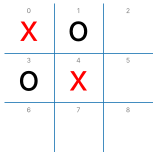


   action  total utility  # of playouts      UCB1
0       2             19             22  1.510669
1       5              9             14  1.453956
2       6             20             23  1.502376
3       7              1              6  1.405641
4       8             35             35  1.512984

Best action: 8
16 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

**Nhận xét – x sắp thắng.** Ô 8 thắng ngay nên mọi playout đều cho +1: điểm trung bình bằng 1,0 và đây là nhánh có số lượt thăm lớn nhất (khoảng 1/3 ngân sách). Ô 2 và ô 6 (tạo đe dọa kép) cũng có điểm cao nên được thăm nhiều hơn ô 5 và ô 7. Với N = 100 mỗi nước chỉ được thăm khoảng 20 lần nên UCB1 chưa loại hẳn được các nước yếu; thành phần khám phá vẫn giữ cho chúng vài lượt thăm (khoảng 5–15 lần), nhờ đó không nhánh nào bị bỏ rơi hoàn toàn.

### o is about to win

Board:


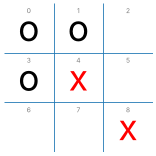


   action  total utility  # of playouts      UCB1
0       2             10            504  0.185406
1       5            -15             27  0.159766
2       6             -2            444  0.171893
3       7            -15             25  0.143384

Best action: 2
129 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

**Nhận xét – o sắp thắng.** Đây là thế cờ thua (o có hai đe dọa ở ô 2 và ô 6). UCB1 dồn gần như toàn bộ ngân sách (thường > 90 %) vào hai nước chặn một đe dọa là ô 2 và ô 6, còn ô 5 và ô 7 (bỏ qua cả hai đe dọa) bị loại sau vài chục lượt thăm. Ô 2 và ô 6 đối xứng qua đường chéo chính nên có kỳ vọng bằng nhau; chênh lệch số lượt thăm giữa chúng chỉ do ngẫu nhiên (nhánh nào "may mắn" lúc đầu sẽ được thăm nhiều hơn) – đây là dao động vô hại.

### x can draw if it chooses 7

Board:


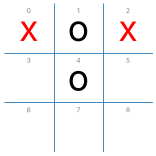

   action  total utility  # of playouts      UCB1
0       3             -8             94  0.298265
1       5             -9             82  0.300709
2       6            -11             22  0.292450
3       7            133            759  0.310146
4       8            -12             43  0.287756

Best action: 7
268 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

**Nhận xét – x cần tìm đường hòa.** Ô 7 (nước duy nhất không thua) có điểm trung bình dương trong khi các nước còn lại âm, nên UCB1 dồn phần lớn playout (thường ≈ 70–80 %) vào ô 7 và chọn đúng. Với cùng ngân sách, PMCS chỉ dành 1/5 số playout (200) cho ô 7 và phần còn lại "lãng phí" cho những nước đã rõ là tệ – đây là điểm khác biệt chính của UCB1: ước lượng nước tốt bằng nhiều mẫu hơn. (Với bài toán nhỏ như Tic-Tac-Toe, quyết định cuối cùng của UCB1 và PMCS khác nhau không nhiều – xem thí nghiệm định lượng ở phần bổ sung.)

### Empty board: Only a draw an be guaranteed

Board:


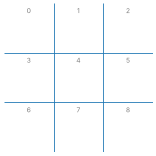


   action  total utility  # of playouts      UCB1
0       0             -2              3  1.085507
1       1              9             21  1.090831
2       2             -1              6  1.072307
3       3             -3              3  0.752174
4       4             10             23  1.067593
5       5              6             17  1.089001
6       6              0              8  1.072983
7       7              1              9  1.122729
8       8              4             10  1.359705

Best action: 4
43.5 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


   action  total utility  # of playouts      UCB1
0       0            103            306  0.572542
1       1             12             90  0.568386
2       2             46            178  0.567779
3       3             65            222  0.569797
4       4           1561           3136  0.571469
5       5             39            160  0.570040
6       6            162            434  0.571387
7       7             53            193  0.571699
8       8             91            281  0.570056

Best action: 4
1.19 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [9]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

**Nhận xét – bàn cờ rỗng.** Với N = 100 (≈ 11 playout/nước) dữ liệu còn quá ít: số lượt thăm giữa các nước chênh nhau ít nên nước được chọn chưa ổn định (có thể là một góc hoặc ô giữa). Với N = 5000 UCB1 tập trung phần lớn playout (thường > 60 %) vào ô giữa (4) – nước tốt nhất theo đánh giá Monte Carlo – và quyết định ổn định hơn rõ rệt. Đây là một phần câu trả lời cho câu hỏi của Bài 6: khi số mô phỏng tăng, quyết định ổn định hơn (được đo định lượng ở phần bổ sung).

### A bad situation

Board:


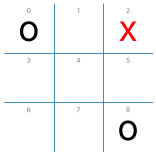


   action  total utility  # of playouts      UCB1
0       1             -3              9  0.678285
1       3             -3             11  0.642316
2       4             13             47  0.719275
3       5             -4              6  0.572307
4       6              0             20  0.678614
5       7             -4              7  0.575639

Best action: 4


4

In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

**Nhận xét – tình huống bất lợi.** UCB1 chọn ô 4 – nước bắt buộc (chặn đường chéo 0‑4‑8 của o) và đồng thời tạo đe dọa ở ô 6. Ô 4 là nhánh duy nhất có điểm trung bình dương nên nhận nhiều lượt thăm nhất (thường ≈ 40 % ngân sách). Như ghi chú của giảng viên bên dưới, o ngẫu nhiên hiếm khi chặn đúng ô 6 (xác suất 1/5) nên bẫy thường thành công; về lý thuyết đây là thế thua, nghĩa là UCB1 (cũng như PMCS) chỉ "tận dụng sai lầm của đối thủ ngẫu nhiên" chứ không đảm bảo nước tối ưu.

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [11]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [12]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 92, 'o': 3, 'd': 5}

974 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 25, 'o': 69, 'd': 6}

569 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [13]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 98, 'o': 0, 'd': 2}

4.88 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 6, 'o': 90, 'd': 4}

4.24 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [14]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 89, 'o': 2, 'd': 9}

5.78 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 28, 'o': 46, 'd': 26}

5.11 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét – UCB1 vs. Random và UCB1 vs. UCB1** (các ô gốc không đặt seed nên số liệu dao động vài ván giữa các lần chạy). UCB1(10) thắng khoảng 90 % số ván khi đi trước và khoảng 70 % khi đi sau trước Random; UCB1(100) thắng gần như toàn bộ khi đi trước (≈ 95–99 %) và khoảng 85–90 % khi đi sau, phần còn lại chủ yếu là hòa. Khi hai UCB1 gặp nhau, UCB1(100) đi trước thắng áp đảo UCB1(10) (≈ 88/100 ván, không thua ván nào hoặc gần như không); khi UCB1(100) đi sau nó vẫn thắng nhiều hơn (khoảng 50 so với 30 ván, còn lại là hòa) nhưng chênh lệch nhỏ hơn nhiều vì lợi thế đi trước của UCB1(10) bù lại một phần. Bảng đầy đủ (có N = 1000, thời gian và so sánh trực tiếp với PMCS) ở phần bổ sung bên dưới.

---
# Lab 05 – Bài 6: Thực hành bổ sung (UCB1 so với Pure Monte Carlo Search)

> Các ô phía trên là nội dung gốc của giảng viên (giữ nguyên); các ô nhận xét được chèn thêm ngay dưới từng thí nghiệm. Phần này thực hiện yêu cầu của Bài 6:
> 1. chạy `ucb1_10_player`, `ucb1_100_player` trên các trạng thái kiểm thử và khi đấu với `random_player`;
> 2. **so sánh với Pure Monte Carlo Search**;
> 3. trả lời hai câu hỏi: *UCB1 cân bằng exploration và exploitation như thế nào?* và *Khi số lần mô phỏng tăng, quyết định có ổn định hơn không?*

## Tóm tắt lý thuyết ngắn: UCB1 cân bằng khai thác – khám phá ra sao?

Với mỗi nước đi $a$ ở độ sâu 1, `UCT_depth1` giữ tổng điểm $u_a$ và số lượt thăm $n_a$; sau $n$ playout, mỗi lần nó chọn nước có chỉ số lớn nhất:

$$\mathrm{UCB1}(a)=\underbrace{\frac{u_a}{n_a}}_{\text{khai thác (exploitation)}}+\underbrace{C\sqrt{\frac{\ln n}{n_a}}}_{\text{khám phá (exploration)}},\qquad C=\sqrt 2 .$$

* **Khai thác:** nước có điểm trung bình cao được chọn lại nhiều lần ⇒ ngân sách tập trung vào nước hứa hẹn.
* **Khám phá:** thưởng giảm theo $1/\sqrt{n_a}$ khi nước $a$ được thăm nhiều, nhưng *tăng chậm* theo $\ln n$ khi các nước khác được thăm ⇒ nước bị bỏ rơi sớm muộn cũng được thử lại; ban đầu chỉ số $=+\infty$ nên mỗi nước được thử ít nhất một lần.
* **Hệ quả:** số lượt thăm của nước kém chỉ tăng cỡ $O(\log n)$, phần lớn ngân sách dồn cho nước tốt. $C=0$ là thuần khai thác (greedy, dễ kẹt vào nước "may mắn" ban đầu); $C$ rất lớn làm phân bổ gần đều, tức quay về PMCS.
* Utility ở đây nằm trong $[-1,1]$ (độ rộng 2) trong khi $C=\sqrt2$ là hằng số lý thuyết cho phần thưởng trong $[0,1]$, nên $C=\sqrt 2$ hơi thiên về khai thác; ta sẽ khảo sát ảnh hưởng của $C$ ở cuối.

In [15]:
import math, time, random
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tictactoe
from tictactoe import check_board
from IPython.display import Markdown

DEBUG = 0    # tắt in bảng của UCT_depth1

def make_board(**cells):
    b = empty_board()
    for symbol, idx in cells.items():
        for i in idx: b[i] = symbol
    return b

# Cùng các trạng thái kiểm thử với phần trên của notebook (và với notebook PMCS)
TESTS = {
    "X sắp thắng"         : make_board(x=[0, 4], o=[1, 3]),
    "X cần tìm đường hòa" : make_board(x=[0, 2], o=[1, 4]),
    "Tình huống bất lợi"  : make_board(x=[2], o=[0, 8]),
    "O sắp thắng"         : make_board(x=[4, 8], o=[0, 1, 3]),
    "Bàn cờ rỗng"         : empty_board(),
}

# --- Bộ giải Minimax chính xác (có nhớ): CHỈ dùng để đánh giá chất lượng nước đi ---
@lru_cache(maxsize=None)
def solve(state, mover):
    g = check_board(list(state))
    if g == 'x': return 1
    if g == 'o': return -1
    if g == 'd': return 0
    vals = []
    for a in tictactoe.actions(list(state)):
        c = list(state); c[a] = mover
        vals.append(solve(tuple(c), other(mover)))
    return max(vals) if mover == 'x' else min(vals)

def action_values(b, mover = 'x'):
    sign = 1 if mover == 'x' else -1
    out = {}
    for a in tictactoe.actions(b):
        c = list(b); c[a] = mover
        out[a] = sign * solve(tuple(c), other(mover))
    return out

def optimal_set(b, mover = 'x'):
    av = action_values(b, mover)
    best = max(av.values())
    return {a for a, v in av.items() if v == best}, len(set(av.values())) > 1

# --- UCT_depth1 có tham số C và trả về số lượt thăm (để phân tích); logic GIỐNG HỆT UCT_depth1 ---
def UCT_depth1_C(board, N = 100, player = 'x', C = math.sqrt(2)):
    acts = actions(board)
    u = [0] * len(acts); n = [0] * len(acts); n_parent = 0
    UCB1 = [+math.inf] * len(acts)
    for i in range(N):
        action_id = UCB1.index(max(UCB1))                 # Select
        p = playout(board, acts[action_id], player = player)   # Simulate
        u[action_id] += p; n[action_id] += 1; n_parent += 1    # Back-propagate
        for k in range(len(acts)):
            if n[k] > 0:
                UCB1[k] = u[k] / n[k] + C * math.sqrt(math.log(n_parent) / n[k])
    return acts, u, n

# --- PMCS (cùng thuật toán như notebook Bài 5) để so sánh: N playout chia đều cho các nước ---
def pmcs_ref(board, N = 100, player = 'x'):
    acts = actions(board)
    n = math.floor(N / len(acts))
    ps = {a: np.mean([playout(board, a, player) for _ in range(n)]) for a in acts}
    return max(ps, key = ps.get)

# Kiểm tra tính nhất quán: cùng seed ⇒ cùng quyết định với UCT_depth1 gốc
for name, b in TESTS.items():
    np.random.seed(7); a1 = UCT_depth1(b, N = 300)
    np.random.seed(7); acts_, u_, n_ = UCT_depth1_C(b, N = 300)
    assert a1 == acts_[n_.index(max(n_))], name
print("UCT_depth1_C cho đúng cùng quyết định với UCT_depth1 gốc (cùng seed) trên cả 5 trạng thái kiểm thử.")

UCT_depth1_C cho đúng cùng quyết định với UCT_depth1 gốc (cùng seed) trên cả 5 trạng thái kiểm thử.


In [16]:
# ---- Độ ổn định: 30 lần chạy lặp lại cho mỗi (thế cờ, N), UCB1 so với PMCS (cùng ngân sách N playout) ----
REPEAT = 30
ALGOS = {"PMCS": lambda b, N: pmcs_ref(b, N = N), "UCB1": lambda b, N: UCT_depth1(b, N = N)}
np.random.seed(2026)
rows = []
for name, b in TESTS.items():
    opt, informative = optimal_set(b)
    for N in (10, 100, 1000):
        rec = {"Trạng thái": name, "N": N, "Nước tối ưu": sorted(opt) if informative else "mọi nước như nhau"}
        for an, f in ALGOS.items():
            picks, times = [], []
            for _ in range(REPEAT):
                t0 = time.perf_counter(); a = f(b, N); times.append((time.perf_counter() - t0) * 1000); picks.append(a)
            cnt = Counter(picks); top, freq = cnt.most_common(1)[0]
            rec[f"{an}: nước hay chọn"] = top
            rec[f"{an}: tần suất"] = f"{freq}/{REPEAT}"
            rec[f"{an}: % chọn nước tối ưu"] = f"{100 * sum(v for k, v in cnt.items() if k in opt) / REPEAT:.0f}%" if informative else "—"
            rec[f"{an}: thời gian TB (ms)"] = round(np.mean(times), 1)
        rows.append(rec)
stab = pd.DataFrame(rows)
display(stab)

,Trạng thái,N,Nước tối ưu,PMCS: nước hay chọn,PMCS: tần suất,PMCS: % chọn nước tối ưu,PMCS: thời gian TB (ms),UCB1: nước hay chọn,UCB1: tần suất,UCB1: % chọn nước tối ưu,UCB1: thời gian TB (ms)
0,X sắp thắng,10,"[2, 6, 8]",2,19/30,83%,1.8,2,20/30,77%,1.9
1,X sắp thắng,100,"[2, 6, 8]",8,30/30,100%,17.2,8,30/30,100%,10.0
2,X sắp thắng,1000,"[2, 6, 8]",8,30/30,100%,93.7,8,30/30,100%,57.0
3,X cần tìm đường hòa,10,[7],7,10/30,33%,1.1,7,9/30,30%,1.1
4,X cần tìm đường hòa,100,[7],7,26/30,87%,11.7,7,28/30,93%,15.4
5,X cần tìm đường hòa,1000,[7],7,30/30,100%,103.1,7,30/30,100%,131.4
6,Tình huống bất lợi,10,mọi nước như nhau,1,11/30,—,0.7,4,17/30,—,1.0
7,Tình huống bất lợi,100,mọi nước như nhau,4,30/30,—,9.4,4,27/30,—,10.9
8,Tình huống bất lợi,1000,mọi nước như nhau,4,30/30,—,129.1,4,30/30,—,118.1
9,O sắp thắng,10,mọi nước như nhau,2,20/30,—,0.5,2,15/30,—,0.6


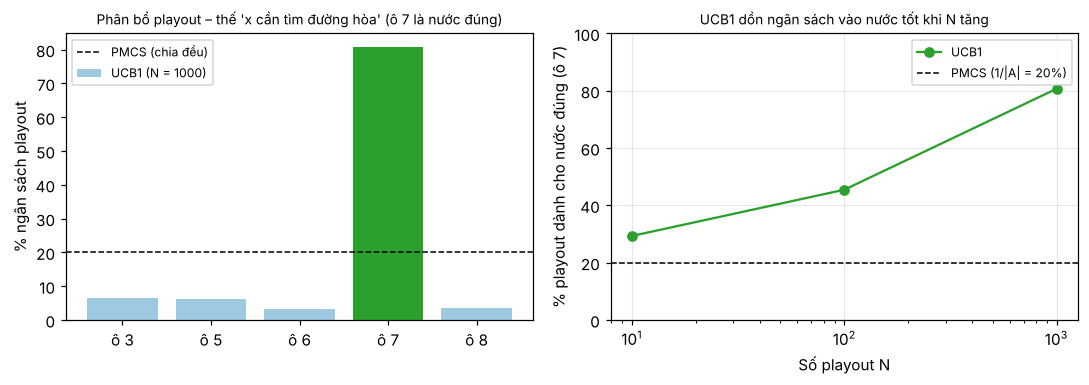

{10: 29.3, 100: 45.5, 1000: 80.7} ← % playout dành cho ô 7 (UCB1)


In [17]:
# ---- Phân bổ playout của UCB1 (trung bình 30 lần chạy) – PMCS luôn chia đều ----
alloc = {}
np.random.seed(2026)
for name in ("X cần tìm đường hòa", "Bàn cờ rỗng"):
    b = TESTS[name]
    for N in (10, 100, 1000):
        tot = np.zeros(len(actions(b)))
        for _ in range(REPEAT):
            _, _, n_ = UCT_depth1_C(b, N = N)
            tot += np.array(n_)
        alloc[(name, N)] = tot / REPEAT / N * 100        # % ngân sách cho từng nước

b = TESTS["X cần tìm đường hòa"]; acts_ = actions(b); best = acts_.index(7)
fig, ax = plt.subplots(1, 2, figsize = (10, 3.6), dpi = 110)
x = np.arange(len(acts_))
ax[0].bar(x, alloc[("X cần tìm đường hòa", 1000)], color = ["#2ca02c" if a == 7 else "#9ecae1" for a in acts_], label = "UCB1 (N = 1000)")
ax[0].axhline(100 / len(acts_), color = "k", ls = "--", lw = 1, label = "PMCS (chia đều)")
ax[0].set_xticks(x); ax[0].set_xticklabels([f"ô {a}" for a in acts_]); ax[0].set_ylabel("% ngân sách playout")
ax[0].set_title("Phân bổ playout – thế 'x cần tìm đường hòa' (ô 7 là nước đúng)", fontsize = 9); ax[0].legend(fontsize = 8)
Ns = [10, 100, 1000]
ax[1].plot(Ns, [alloc[("X cần tìm đường hòa", N)][best] for N in Ns], "o-", color = "#2ca02c", label = "UCB1")
ax[1].axhline(100 / len(acts_), color = "k", ls = "--", lw = 1, label = "PMCS (1/|A| = 20%)")
ax[1].set_xscale("log"); ax[1].set_ylim(0, 100); ax[1].set_xlabel("Số playout N"); ax[1].set_ylabel("% playout dành cho nước đúng (ô 7)")
ax[1].set_title("UCB1 dồn ngân sách vào nước tốt khi N tăng", fontsize = 9); ax[1].legend(fontsize = 8); ax[1].grid(alpha = .3)
plt.tight_layout(); plt.show()
print({N: round(float(alloc[("X cần tìm đường hòa", N)][best]), 1) for N in Ns}, "← % playout dành cho ô 7 (UCB1)")

,N,PMCS: % nước tối ưu,UCB1: % nước tối ưu
0,10,84.0,83.0
1,100,94.5,95.5
2,1000,95.5,97.0


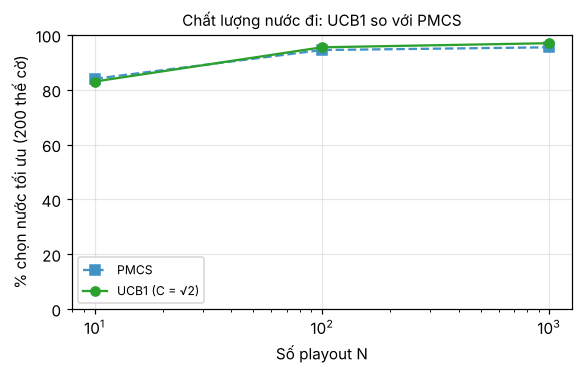

In [18]:
# ---- Chất lượng nước đi trên 200 thế cờ "có phân biệt nước tốt/xấu" (cùng mẫu với notebook PMCS) ----
start = tuple(empty_board())
reach, frontier = {start: 'x'}, [(start, 'x')]
while frontier:
    nxt = []
    for s, p in frontier:
        if check_board(list(s)) != 'n': continue
        for a in tictactoe.actions(list(s)):
            c = list(s); c[a] = p; c = tuple(c)
            if c not in reach:
                reach[c] = other(p); nxt.append((c, other(p)))
    frontier = nxt
informative_states = [(list(s), p) for s, p in reach.items()
                      if check_board(list(s)) == 'n' and optimal_set(list(s), p)[1]]
sample = random.Random(2026).sample(informative_states, 200)

def quality(fun, N, states):
    ok = 0
    for b, p in states:
        opt, _ = optimal_set(b, p)
        ok += (fun(b, N, p) in opt)
    return 100 * ok / len(states)

np.random.seed(2026)
qrows = []
for N in (10, 100, 1000):
    qrows.append({"N": N,
                  "PMCS: % nước tối ưu": quality(lambda b, N, p: pmcs_ref(b, N, p), N, sample),
                  "UCB1: % nước tối ưu": quality(lambda b, N, p: UCT_depth1(b, N, p), N, sample)})
q = pd.DataFrame(qrows).round(1)
display(q)

fig, ax = plt.subplots(figsize = (5.4, 3.5), dpi = 110)
ax.plot(q["N"], q["PMCS: % nước tối ưu"], "s--", color = "#4292c6", label = "PMCS")
ax.plot(q["N"], q["UCB1: % nước tối ưu"], "o-", color = "#2ca02c", label = "UCB1 (C = √2)")
ax.set_xscale("log"); ax.set_ylim(0, 100); ax.set_xlabel("Số playout N"); ax.set_ylabel("% chọn nước tối ưu (200 thế cờ)")
ax.set_title("Chất lượng nước đi: UCB1 so với PMCS", fontsize = 10); ax.grid(alpha = .3); ax.legend(fontsize = 8)
plt.tight_layout(); plt.show()

,N,C,% chọn nước tối ưu,% playout dành cho nước tối ưu
0,100,0,92.0,90.3
1,100,"0,5",99.0,92.5
2,100,1,98.0,87.4
3,100,√2,97.0,82.8
4,100,2√2,96.0,72.2
5,100,6,97.0,60.9
6,1000,0,92.0,91.6
7,1000,"0,5",99.0,98.2
8,1000,1,100.0,96.7
9,1000,√2,98.0,94.1


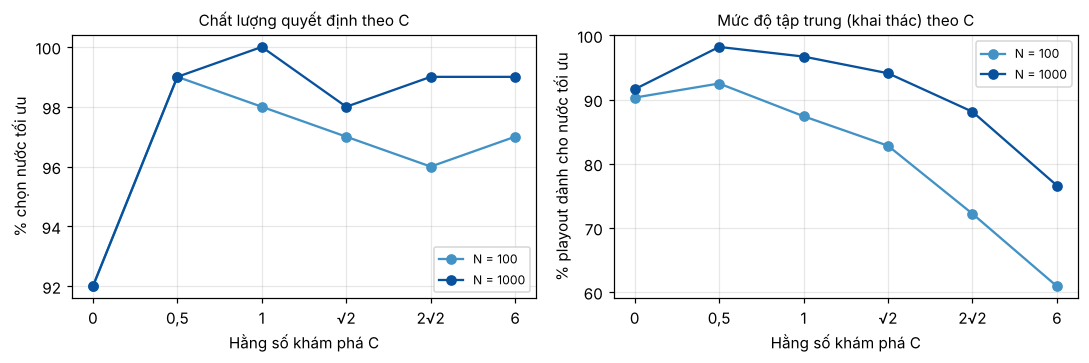

In [19]:
# ---- Ảnh hưởng của hằng số khám phá C (100 thế cờ đầu của mẫu trên) ----
Cs = [0, 0.5, 1, math.sqrt(2), 2 * math.sqrt(2), 6]
labels = ["0", "0,5", "1", "√2", "2√2", "6"]
sub = sample[:100]
np.random.seed(2026)
crow = []
for N in (100, 1000):
    for C_, lab in zip(Cs, labels):
        ok, share = 0, 0.0
        for b, p in sub:
            opt, _ = optimal_set(b, p)
            acts_, u_, n_ = UCT_depth1_C(b, N = N, player = p, C = C_)
            ok += (acts_[n_.index(max(n_))] in opt)
            share += sum(n_[i] for i, a in enumerate(acts_) if a in opt) / N
        crow.append({"N": N, "C": lab, "% chọn nước tối ưu": 100 * ok / len(sub), "% playout dành cho nước tối ưu": 100 * share / len(sub)})
cs = pd.DataFrame(crow).round(1)
display(cs)

fig, ax = plt.subplots(1, 2, figsize = (10, 3.4), dpi = 110)
for N, col in ((100, "#4292c6"), (1000, "#08519c")):
    d = cs[cs["N"] == N]
    ax[0].plot(labels, d["% chọn nước tối ưu"], "o-", color = col, label = f"N = {N}")
    ax[1].plot(labels, d["% playout dành cho nước tối ưu"], "o-", color = col, label = f"N = {N}")
ax[0].set_ylabel("% chọn nước tối ưu"); ax[1].set_ylabel("% playout dành cho nước tối ưu")
for a_, t in zip(ax, ("Chất lượng quyết định theo C", "Mức độ tập trung (khai thác) theo C")):
    a_.set_xlabel("Hằng số khám phá C"); a_.set_title(t, fontsize = 10); a_.grid(alpha = .3); a_.legend(fontsize = 8)
plt.tight_layout(); plt.show()

In [20]:
# ---- Bảng UCB1 vs. Random: N = 10, 100, 1000 (mỗi vai 100 ván, seed cố định) ----
def ucb1_1000_player(board, player = 'x'):
    return UCT_depth1(board, N = 1000, player = player)

def timed(agent, stats):
    def f(board, player = 'x'):
        t = time.perf_counter(); a = agent(board, player)
        stats["t"] += time.perf_counter() - t; stats["n"] += 1
        return a
    return f

UCB = {10: ucb1_10_player, 100: ucb1_100_player, 1000: ucb1_1000_player}
GAMES = 100
np.random.seed(2026)
rows = []
for N, agent in UCB.items():
    for role in ("x", "o"):
        st = {"t": 0.0, "n": 0}
        a = timed(agent, st)
        r = play(a, random_player, N = GAMES) if role == "x" else play(random_player, a, N = GAMES)
        win, loss = (r['x'], r['o']) if role == "x" else (r['o'], r['x'])
        rows.append({"N": N, "Vai": role, "Số ván": GAMES, "Thắng": win, "Hòa": r['d'], "Thua": loss,
                     "Thời gian TB / nước (ms)": round(1000 * st["t"] / st["n"], 2), "_t": st["t"], "_n": st["n"]})
um = pd.DataFrame(rows)
display(um.drop(columns = ["_t", "_n"]))

ufinal_rows = []
for N in UCB:
    s = um[um["N"] == N]
    games, w, d_, l = s["Số ván"].sum(), s["Thắng"].sum(), s["Hòa"].sum(), s["Thua"].sum()
    wx = int(s[s["Vai"] == "x"]["Thắng"].iloc[0]); wo = int(s[s["Vai"] == "o"]["Thắng"].iloc[0])
    ufinal_rows.append({"Số playout N": N,
                        "Tỷ lệ thắng": f"{100 * w / games:.1f}%", "Tỷ lệ hòa": f"{100 * d_ / games:.1f}%", "Tỷ lệ thua": f"{100 * l / games:.1f}%",
                        "Thời gian TB / nước (ms)": round(1000 * s["_t"].sum() / s["_n"].sum(), 2),
                        "Nhận xét": f"Thắng {100 * wx / GAMES:.0f}% khi đi trước, {100 * wo / GAMES:.0f}% khi đi sau; thua {l}/{games} ván"})
ufinal = pd.DataFrame(ufinal_rows)
display(ufinal)

,N,Vai,Số ván,Thắng,Hòa,Thua,Thời gian TB / nước (ms)
0,10,x,100,95,3,2,1.38
1,10,o,100,61,12,27,1.14
2,100,x,100,98,2,0,14.05
3,100,o,100,87,2,11,12.01
4,1000,x,100,97,3,0,133.71
5,1000,o,100,92,4,4,111.57


,Số playout N,Tỷ lệ thắng,Tỷ lệ hòa,Tỷ lệ thua,Thời gian TB / nước (ms),Nhận xét
0,10,78.0%,7.5%,14.5%,1.26,"Thắng 95% khi đi trước, 61% khi đi sau; thua 2..."
1,100,92.5%,2.0%,5.5%,13.06,"Thắng 98% khi đi trước, 87% khi đi sau; thua 1..."
2,1000,94.5%,3.5%,2.0%,122.79,"Thắng 97% khi đi trước, 92% khi đi sau; thua 4..."


In [21]:
# ---- So sánh trực tiếp UCB1 với PMCS (cùng N playout), mỗi vai 100 ván ----
def pmcs_player(N):
    return lambda board, player = 'x': pmcs_ref(board, N = N, player = player)

def score_line(w, d_, l, g):
    s = (w + 0.5 * d_) / g
    var = (w + 0.25 * d_) / g - s * s
    return s, 2 * (var / g) ** 0.5            # điểm trung bình (thắng = 1, hòa = 0,5) và nửa độ rộng khoảng tin cậy ≈ 95 %

np.random.seed(2026)
hh = []
for N in (10, 100):
    u, p = UCB[N], pmcs_player(N)
    r1 = play(u, p, N = GAMES)                     # UCB1 đi trước
    r2 = play(p, u, N = GAMES)                     # UCB1 đi sau
    w, d_, l = r1['x'] + r2['o'], r1['d'] + r2['d'], r1['o'] + r2['x']
    s, ci = score_line(w, d_, l, 2 * GAMES)
    hh.append({"N": N, "UCB1 đi trước (T-H-B)": f"{r1['x']}-{r1['d']}-{r1['o']}", "UCB1 đi sau (T-H-B)": f"{r2['o']}-{r2['d']}-{r2['x']}",
               "Tổng (T-H-B)": f"{w}-{d_}-{l}", "Điểm UCB1 (thắng=1, hòa=½)": f"{s:.3f} ± {ci:.3f}"})
hh = pd.DataFrame(hh)
display(hh)

,N,UCB1 đi trước (T-H-B),UCB1 đi sau (T-H-B),Tổng (T-H-B),"Điểm UCB1 (thắng=1, hòa=½)"
0,10,62-11-27,32-7-61,94-18-88,0.515 ± 0.067
1,100,63-33-4,12-35-53,75-68-57,0.545 ± 0.057


In [22]:
# Câu trả lời tự động từ số liệu vừa đo (luôn nhất quán với các bảng ở trên)
vn = lambda x, d = 0: f"{x:.{d}f}".replace(".", ",")
def freq_mean(an, N):
    s = stab[stab["N"] == N][f"{an}: tần suất"].str.split("/").str[0].astype(int)
    return 100 * s.mean() / REPEAT
def opt_mean(an, N):
    s = stab[(stab["N"] == N) & (stab[f"{an}: % chọn nước tối ưu"] != "—")][f"{an}: % chọn nước tối ưu"].str.rstrip("%").astype(float)
    return s.mean()
share = {N: float(alloc[("X cần tìm đường hòa", N)][best]) for N in (10, 100, 1000)}
cs100 = cs[cs["N"] == 100].set_index("C"); cs1000 = cs[cs["N"] == 1000].set_index("C")
qq = q.set_index("N")
wr = {r["Số playout N"]: r["Tỷ lệ thắng"].replace(".", ",") for r in ufinal_rows}
ls = {N: int(um[um["N"] == N]["Thua"].sum()) for N in UCB}

# --- câu 1: vai trò của C (nhận xét có điều kiện theo số liệu) ---
q0, qs, q6 = cs100.loc['0', '% chọn nước tối ưu'], cs100.loc['√2', '% chọn nước tối ưu'], cs100.loc['6', '% chọn nước tối ưu']
q0b, qsb, q6b = cs1000.loc['0', '% chọn nước tối ưu'], cs1000.loc['√2', '% chọn nước tối ưu'], cs1000.loc['6', '% chọn nước tối ưu']
bestC = cs1000['% playout dành cho nước tối ưu'].idxmax()
if min(q0, q0b) < min(qs, qsb):
    c_note = "⇒ thiếu khám phá ($C=0$) có xu hướng làm giảm chất lượng quyết định (kém vài điểm phần trăm; chênh lệch nhỏ vì Tic-Tac-Toe rất đơn giản)."
else:
    c_note = "⇒ trên tập thế cờ này, thiếu khám phá ($C=0$) chưa làm giảm rõ rệt chất lượng quyết định cuối cùng (độ ổn định/độ tập trung mới là chỗ khác biệt)."

# --- câu 2: độ ổn định theo N ---
f10, f1000 = freq_mean('UCB1', 10), freq_mean('UCB1', 1000)
stable_word = "Có" if f1000 > f10 else "Không rõ rệt"

# --- câu 3: so sánh UCB1 với PMCS ---
d_q = {N: qq.loc[N, 'UCB1: % nước tối ưu'] - qq.loc[N, 'PMCS: % nước tối ưu'] for N in (10, 100, 1000)}
mean_d = float(np.mean(list(d_q.values())))
if abs(mean_d) < 2.5:
    cmp_q = "chất lượng nước đi của hai thuật toán **tương đương** (chênh lệch nằm trong sai số lấy mẫu của 200 thế cờ, cỡ ±2–3 điểm phần trăm)."
elif mean_d >= 2.5:
    cmp_q = "UCB1 chọn nước tối ưu nhiều hơn PMCS rõ rệt với cùng ngân sách."
else:
    cmp_q = "PMCS chọn nước tối ưu nhiều hơn UCB1 rõ rệt trên mẫu này."
row100 = hh[hh["N"] == 100].iloc[0]
s100, ci100 = [float(v) for v in row100["Điểm UCB1 (thắng=1, hòa=½)"].replace("±", " ").split()]
if s100 - 0.5 > ci100:   duel = "UCB1 thắng PMCS có ý nghĩa thống kê"
elif 0.5 - s100 > ci100: duel = "PMCS thắng UCB1 có ý nghĩa thống kê"
else:                    duel = "hai thuật toán không khác biệt có ý nghĩa thống kê (độ chênh nằm trong khoảng tin cậy)"

display(Markdown(f"""
### Trả lời các câu hỏi của Bài 6 (số liệu từ các ô có seed cố định ở trên)

**1. UCB1 cân bằng exploration và exploitation như thế nào?**
* **Khai thác:** ở thế "x cần tìm đường hòa" UCB1 dành {vn(share[10])} % → {vn(share[100])} % → {vn(share[1000])} % số playout cho nước đúng (ô 7) khi N = 10 → 100 → 1000, trong khi PMCS luôn chỉ dành 20 % (chia đều cho 5 nước). Ngân sách được dồn dần vào nước có điểm trung bình cao.
* **Khám phá:** thưởng $C\\sqrt{{\\ln n/n_a}}$ giữ cho các nước kém vẫn được thử lại với tần suất giảm dần (cỡ $\\log n$), nên một đánh giá sai lúc đầu (do may rủi) có cơ hội được sửa.
* **Vai trò của hằng số $C$** (100 thế cờ, N = 100 và N = 1000): tỉ lệ chọn đúng nước tối ưu là {vn(q0)} % và {vn(q0b)} % với $C=0$ (thuần khai thác); {vn(qs)} % và {vn(qsb)} % với $C=\\sqrt2$; {vn(q6)} % và {vn(q6b)} % với $C=6$ (thiên về khám phá, gần chia đều như PMCS) {c_note} Tỉ lệ playout dành cho nước tối ưu (N = 1000) cao nhất ở $C$ = {bestC} ({vn(cs1000.loc[bestC, '% playout dành cho nước tối ưu'])} %) và giảm còn {vn(cs1000.loc['6', '% playout dành cho nước tối ưu'])} % khi $C=6$: $C$ càng lớn thì ngân sách càng được phân tán (nghiêng về khám phá).

**2. Khi số lần mô phỏng tăng, quyết định có ổn định hơn không?** — **{stable_word}.**
* Trong 30 lần chạy lặp lại trên 5 thế cờ, nước được chọn nhiều nhất chiếm trung bình {vn(freq_mean('UCB1', 10))} % → {vn(freq_mean('UCB1', 100))} % → {vn(freq_mean('UCB1', 1000))} % số lần với UCB1 (và {vn(freq_mean('PMCS', 10))} % → {vn(freq_mean('PMCS', 100))} % → {vn(freq_mean('PMCS', 1000))} % với PMCS) khi N = 10 → 100 → 1000.
* Ở các thế cờ có nước tối ưu phân biệt được, tỉ lệ chọn đúng là {vn(opt_mean('UCB1', 10))} % → {vn(opt_mean('UCB1', 100))} % → {vn(opt_mean('UCB1', 1000))} % (UCB1) và {vn(opt_mean('PMCS', 10))} % → {vn(opt_mean('PMCS', 100))} % → {vn(opt_mean('PMCS', 1000))} % (PMCS); trên 200 thế cờ ngẫu nhiên là {vn(qq.loc[10, 'UCB1: % nước tối ưu'])} % → {vn(qq.loc[100, 'UCB1: % nước tối ưu'])} % → {vn(qq.loc[1000, 'UCB1: % nước tối ưu'])} % (UCB1) so với {vn(qq.loc[10, 'PMCS: % nước tối ưu'])} % → {vn(qq.loc[100, 'PMCS: % nước tối ưu'])} % → {vn(qq.loc[1000, 'PMCS: % nước tối ưu'])} % (PMCS).
* Vẫn còn dao động ở các thế cờ có hai nước *tương đương* (ô 2/6 ở thế "o sắp thắng", các góc ở bàn cờ rỗng) – đó là dao động vô hại – và khi chênh lệch giữa các nước nhỏ hơn sai số lấy mẫu.

**3. So sánh với Pure Monte Carlo Search.**
* **Chất lượng nước đi** (200 thế cờ, UCB1 trừ PMCS): {vn(d_q[10], 1)} / {vn(d_q[100], 1)} / {vn(d_q[1000], 1)} điểm phần trăm ở N = 10 / 100 / 1000 ⇒ {cmp_q}
* **Trước Random:** UCB1 thắng {wr[10]} (N = 10), {wr[100]} (N = 100), {wr[1000]} (N = 1000), thua {ls[10]} → {ls[100]} → {ls[1000]} ván trên 200 ván. Random là đối thủ yếu nên cả hai thuật toán đều thắng áp đảo; sự khác biệt chủ yếu nằm ở độ chính xác của quyết định.
* **Đối đầu trực tiếp (N = 100, 200 ván):** điểm của UCB1 = {row100['Điểm UCB1 (thắng=1, hòa=½)'].replace('.', ',')} ⇒ {duel}.
* **Kết luận:** UCB1 và PMCS có chi phí tính toán gần như bằng nhau (UCB1 chỉ thêm vòng cập nhật chỉ số cho từng nước). Về *chất lượng quyết định* trên Tic-Tac-Toe hai thuật toán gần như không khác nhau (xem trên). Khác biệt rõ nhất nằm ở **cách dùng ngân sách**: ở N = 1000 UCB1 dồn {vn(share[1000])} % playout vào nước đúng (PMCS: 20 %), nên nước tốt được ước lượng bằng nhiều mẫu hơn hẳn. Lợi thế này chỉ chuyển thành kết quả tốt hơn khi bài toán đủ khó – nhiều nước đi, cây sâu hoặc mỗi playout tốn kém – còn Tic-Tac-Toe quá nhỏ nên N = 100–1000 đã đủ cho cả hai. Cả hai đều dùng chính sách playout ngẫu nhiên nên vẫn đánh giá thế cờ như thể đối thủ chơi tệ; UCB1 độ sâu 1 cũng chưa xây cây nhiều tầng như UCT/MCTS đầy đủ.
"""))


### Trả lời các câu hỏi của Bài 6 (số liệu từ các ô có seed cố định ở trên)

**1. UCB1 cân bằng exploration và exploitation như thế nào?**
* **Khai thác:** ở thế "x cần tìm đường hòa" UCB1 dành 29 % → 45 % → 81 % số playout cho nước đúng (ô 7) khi N = 10 → 100 → 1000, trong khi PMCS luôn chỉ dành 20 % (chia đều cho 5 nước). Ngân sách được dồn dần vào nước có điểm trung bình cao.
* **Khám phá:** thưởng $C\sqrt{\ln n/n_a}$ giữ cho các nước kém vẫn được thử lại với tần suất giảm dần (cỡ $\log n$), nên một đánh giá sai lúc đầu (do may rủi) có cơ hội được sửa.
* **Vai trò của hằng số $C$** (100 thế cờ, N = 100 và N = 1000): tỉ lệ chọn đúng nước tối ưu là 92 % và 92 % với $C=0$ (thuần khai thác); 97 % và 98 % với $C=\sqrt2$; 97 % và 99 % với $C=6$ (thiên về khám phá, gần chia đều như PMCS) ⇒ thiếu khám phá ($C=0$) có xu hướng làm giảm chất lượng quyết định (kém vài điểm phần trăm; chênh lệch nhỏ vì Tic-Tac-Toe rất đơn giản). Tỉ lệ playout dành cho nước tối ưu (N = 1000) cao nhất ở $C$ = 0,5 (98 %) và giảm còn 77 % khi $C=6$: $C$ càng lớn thì ngân sách càng được phân tán (nghiêng về khám phá).

**2. Khi số lần mô phỏng tăng, quyết định có ổn định hơn không?** — **Có.**
* Trong 30 lần chạy lặp lại trên 5 thế cờ, nước được chọn nhiều nhất chiếm trung bình 53 % → 75 % → 89 % số lần với UCB1 (và 51 % → 74 % → 85 % với PMCS) khi N = 10 → 100 → 1000.
* Ở các thế cờ có nước tối ưu phân biệt được, tỉ lệ chọn đúng là 54 % → 96 % → 100 % (UCB1) và 58 % → 94 % → 100 % (PMCS); trên 200 thế cờ ngẫu nhiên là 83 % → 96 % → 97 % (UCB1) so với 84 % → 94 % → 96 % (PMCS).
* Vẫn còn dao động ở các thế cờ có hai nước *tương đương* (ô 2/6 ở thế "o sắp thắng", các góc ở bàn cờ rỗng) – đó là dao động vô hại – và khi chênh lệch giữa các nước nhỏ hơn sai số lấy mẫu.

**3. So sánh với Pure Monte Carlo Search.**
* **Chất lượng nước đi** (200 thế cờ, UCB1 trừ PMCS): -1,0 / 1,0 / 1,5 điểm phần trăm ở N = 10 / 100 / 1000 ⇒ chất lượng nước đi của hai thuật toán **tương đương** (chênh lệch nằm trong sai số lấy mẫu của 200 thế cờ, cỡ ±2–3 điểm phần trăm).
* **Trước Random:** UCB1 thắng 78,0% (N = 10), 92,5% (N = 100), 94,5% (N = 1000), thua 29 → 11 → 4 ván trên 200 ván. Random là đối thủ yếu nên cả hai thuật toán đều thắng áp đảo; sự khác biệt chủ yếu nằm ở độ chính xác của quyết định.
* **Đối đầu trực tiếp (N = 100, 200 ván):** điểm của UCB1 = 0,545 ± 0,057 ⇒ hai thuật toán không khác biệt có ý nghĩa thống kê (độ chênh nằm trong khoảng tin cậy).
* **Kết luận:** UCB1 và PMCS có chi phí tính toán gần như bằng nhau (UCB1 chỉ thêm vòng cập nhật chỉ số cho từng nước). Về *chất lượng quyết định* trên Tic-Tac-Toe hai thuật toán gần như không khác nhau (xem trên). Khác biệt rõ nhất nằm ở **cách dùng ngân sách**: ở N = 1000 UCB1 dồn 81 % playout vào nước đúng (PMCS: 20 %), nên nước tốt được ước lượng bằng nhiều mẫu hơn hẳn. Lợi thế này chỉ chuyển thành kết quả tốt hơn khi bài toán đủ khó – nhiều nước đi, cây sâu hoặc mỗi playout tốn kém – còn Tic-Tac-Toe quá nhỏ nên N = 100–1000 đã đủ cho cả hai. Cả hai đều dùng chính sách playout ngẫu nhiên nên vẫn đánh giá thế cờ như thể đối thủ chơi tệ; UCB1 độ sâu 1 cũng chưa xây cây nhiều tầng như UCT/MCTS đầy đủ.
